# People Analytics: Análisis de Rotación y Retención de Personal

## Problema de negocio

Una empresa con varias sucursales presenta rotación frecuente de personal y necesita identificar en qué segmentos se concentran las salidas para orientar acciones de retención.

## Pregunta principal

¿Qué factores están asociados con una mayor rotación de personal y qué grupos deberían priorizarse para investigar posibles problemas de retención?

## Objetivo

Analizar la rotación según departamento, sucursal, turno, antigüedad, tipo de contrato y condiciones laborales para detectar segmentos críticos y generar recomendaciones de negocio.

## Datos

Se utilizará un dataset sintético de 1.500 empleados creado exclusivamente con fines educativos y de portafolio. Los resultados representan un escenario simulado y no corresponden a una empresa real.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

np.random.seed(42)

n = 1500
fecha_corte = pd.Timestamp("2026-10-31")

df = pd.DataFrame({
    "empleado_id": range(1, n + 1),

    "sucursal": np.random.choice(
        ["Ñuñoa", "Providencia", "Santiago Centro", "Maipú"],
        size=n,
        p=[0.28, 0.25, 0.27, 0.20]
    ),

    "departamento": np.random.choice(
        ["Operaciones", "Ventas", "Administración", "Atención al cliente"],
        size=n,
        p=[0.38, 0.25, 0.15, 0.22]
    ),

    "turno": np.random.choice(
        ["Mañana", "Tarde", "Noche"],
        size=n,
        p=[0.45, 0.38, 0.17]
    ),

    "tipo_contrato": np.random.choice(
        ["Indefinido", "Plazo fijo"],
        size=n,
        p=[0.72, 0.28]
    ),

    "horas_extra_mes": np.clip(
        np.random.normal(8, 5, n),
        0,
        30
    ).round(1),

    "dias_ausencia_12m": np.clip(
        np.random.poisson(4, n),
        0,
        20
    ),

    "capacitaciones_12m": np.random.choice(
        [0, 1, 2, 3, 4],
        size=n,
        p=[0.18, 0.30, 0.28, 0.16, 0.08]
    ),

    "satisfaccion": np.random.choice(
        [1, 2, 3, 4, 5],
        size=n,
        p=[0.08, 0.17, 0.35, 0.28, 0.12]
    ),

    "evaluacion_desempeno": np.random.choice(
        [1, 2, 3, 4, 5],
        size=n,
        p=[0.03, 0.12, 0.42, 0.33, 0.10]
    )
})

# -----------------------------
# Fecha de ingreso
# -----------------------------

dias_desde_2019 = (
    fecha_corte - pd.Timestamp("2019-01-01")
).days

df["fecha_ingreso"] = (
    pd.Timestamp("2019-01-01")
    + pd.to_timedelta(
        np.random.randint(
            0,
            dias_desde_2019 + 1,
            n
        ),
        unit="D"
    )
)

# -----------------------------
# Antigüedad potencial
# -----------------------------

df["antiguedad_potencial_meses"] = (
    (fecha_corte - df["fecha_ingreso"]).dt.days
    / 30.44
).round(1)

# -----------------------------
# Probabilidad sintética de salida
# -----------------------------

riesgo = np.full(n, 0.08)

riesgo += np.where(
    df["departamento"] == "Operaciones",
    0.08,
    0
)

riesgo += np.where(
    df["turno"] == "Noche",
    0.10,
    0
)

riesgo += np.where(
    df["tipo_contrato"] == "Plazo fijo",
    0.09,
    0
)

riesgo += np.where(
    df["horas_extra_mes"] > 12,
    0.07,
    0
)

riesgo += np.where(
    df["satisfaccion"] <= 2,
    0.12,
    0
)

riesgo += np.where(
    df["capacitaciones_12m"] == 0,
    0.05,
    0
)

riesgo += np.where(
    df["antiguedad_potencial_meses"] < 18,
    0.08,
    0
)

riesgo = np.clip(
    riesgo,
    0.03,
    0.65
)

df["salio_empresa"] = np.random.binomial(
    1,
    riesgo
)

# -----------------------------
# Fecha de salida
# -----------------------------

df["fecha_salida"] = pd.Series(
    pd.NaT,
    index=df.index,
    dtype="datetime64[ns]"
)

for i in df.index[df["salio_empresa"] == 1]:

    max_dias = (
        fecha_corte
        - df.loc[i, "fecha_ingreso"]
    ).days

    if max_dias > 30:

        dias_hasta_salida = np.random.randint(
            30,
            max_dias + 1
        )

        df.loc[i, "fecha_salida"] = (
            df.loc[i, "fecha_ingreso"]
            + pd.Timedelta(
                days=dias_hasta_salida
            )
        )

    else:

        df.loc[i, "fecha_salida"] = fecha_corte

# -----------------------------
# Antigüedad real
# -----------------------------

df["fecha_fin"] = df["fecha_salida"].fillna(
    fecha_corte
)

df["antiguedad_meses"] = (
    (
        df["fecha_fin"]
        - df["fecha_ingreso"]
    ).dt.days / 30.44
).round(1)

df["estado"] = np.where(
    df["salio_empresa"] == 1,
    "Salió",
    "Activo"
)

df = df.drop(
    columns=[
        "antiguedad_potencial_meses",
        "fecha_fin"
    ]
)

df.head()

,empleado_id,sucursal,departamento,turno,tipo_contrato,horas_extra_mes,dias_ausencia_12m,capacitaciones_12m,satisfaccion,evaluacion_desempeno,fecha_ingreso,salio_empresa,fecha_salida,antiguedad_meses,estado
0,1,Providencia,Ventas,Tarde,Indefinido,2.8,5,2,5,4,2022-07-06,1,2026-09-19,50.5,Salió
1,2,Maipú,Ventas,Tarde,Indefinido,10.4,0,1,4,3,2022-09-08,0,NaT,49.7,Activo
2,3,Santiago Centro,Operaciones,Mañana,Indefinido,9.5,3,1,4,4,2026-01-21,0,NaT,9.3,Activo
3,4,Santiago Centro,Operaciones,Tarde,Indefinido,12.8,4,0,4,4,2025-06-06,0,NaT,16.8,Activo
4,5,Ñuñoa,Ventas,Tarde,Indefinido,4.0,7,2,4,3,2024-03-03,0,NaT,31.9,Activo


## 1. Auditoría y calidad de los datos

Antes del análisis se revisan estructura, tipos de datos, valores nulos, duplicados e IDs únicos.

Los valores vacíos en `fecha_salida` son esperados: corresponden a empleados que continúan activos.

In [ ]:
print("Dimensiones:", df.shape)

print("\nDuplicados:")
print(df.duplicated().sum())

print("\nIDs únicos:")
print(df["empleado_id"].nunique())

print("\nValores nulos:")
print(df.isnull().sum())

print("\nTipos de datos:")
print(df.dtypes)

rotacion_general = round(
    df["salio_empresa"].mean() * 100,
    2
)

print(
    "\nRotación general:",
    rotacion_general,
    "%"
)


def resumen_rotacion(campo, ordenar=True):

    tabla = (
        df.groupby(
            campo,
            observed=True
        )
        .agg(
            empleados=("empleado_id", "count"),
            salidas=("salio_empresa", "sum"),
            tasa_rotacion=("salio_empresa", "mean")
        )
        .reset_index()
    )

    tabla["tasa_rotacion"] = (
        tabla["tasa_rotacion"] * 100
    ).round(2)

    if ordenar:

        tabla = tabla.sort_values(
            "tasa_rotacion",
            ascending=False
        )

    return tabla


rotacion_sucursal = resumen_rotacion(
    "sucursal"
)

rotacion_departamento = resumen_rotacion(
    "departamento"
)

rotacion_turno = resumen_rotacion(
    "turno"
)

rotacion_depto_turno = resumen_rotacion(
    ["departamento", "turno"]
)


print("\nROTACIÓN POR SUCURSAL")
display(rotacion_sucursal)

print("\nROTACIÓN POR DEPARTAMENTO")
display(rotacion_departamento)

print("\nROTACIÓN POR TURNO")
display(rotacion_turno)

print("\nDEPARTAMENTO + TURNO")
display(rotacion_depto_turno)

Dimensiones: (1500, 15)

Duplicados:
0

IDs únicos:
1500

Valores nulos:
empleado_id                0
sucursal                   0
departamento               0
turno                      0
tipo_contrato              0
horas_extra_mes            0
dias_ausencia_12m          0
capacitaciones_12m         0
satisfaccion               0
evaluacion_desempeno       0
fecha_ingreso              0
salio_empresa              0
fecha_salida            1166
antiguedad_meses           0
estado                     0
dtype: int64

Tipos de datos:
empleado_id                      int64
sucursal                        object
departamento                    object
turno                           object
tipo_contrato                   object
horas_extra_mes                float64
dias_ausencia_12m                int64
capacitaciones_12m               int64
satisfaccion                     int64
evaluacion_desempeno             int64
fecha_ingreso           datetime64[ns]
salio_empresa                    

,sucursal,empleados,salidas,tasa_rotacion
0,Maipú,311,71,22.83
2,Santiago Centro,404,91,22.52
1,Providencia,345,77,22.32
3,Ñuñoa,440,95,21.59



ROTACIÓN POR DEPARTAMENTO


,departamento,empleados,salidas,tasa_rotacion
2,Operaciones,561,152,27.09
3,Ventas,376,86,22.87
0,Administración,230,44,19.13
1,Atención al cliente,333,52,15.62



ROTACIÓN POR TURNO


,turno,empleados,salidas,tasa_rotacion
1,Noche,224,61,27.23
0,Mañana,701,156,22.25
2,Tarde,575,117,20.35



DEPARTAMENTO + TURNO


,departamento,turno,empleados,salidas,tasa_rotacion
7,Operaciones,Noche,84,26,30.95
8,Operaciones,Tarde,201,60,29.85
10,Ventas,Noche,58,17,29.31
9,Ventas,Mañana,155,38,24.52
4,Atención al cliente,Noche,49,12,24.49
6,Operaciones,Mañana,276,66,23.91
0,Administración,Mañana,112,26,23.21
11,Ventas,Tarde,163,31,19.02
1,Administración,Noche,33,6,18.18
3,Atención al cliente,Mañana,158,26,16.46


## 2. Primeros hallazgos

La rotación general del escenario es de **22,27%**.

**Operaciones** presenta la mayor tasa por departamento, con **27,09%**.

El turno **Noche** registra la mayor rotación, con **27,23%**.

La combinación **Operaciones + Noche** alcanza la tasa más alta, con **30,95%**. Sin embargo, **Operaciones + Tarde** presenta una tasa similar de **29,85%** y concentra 60 salidas, por lo que representa un impacto operativo relevante.

Las diferencias entre sucursales son mucho menores, entre aproximadamente 21,6% y 22,8%, por lo que la sucursal no aparece inicialmente como uno de los principales factores de segmentación.

## 3. Antigüedad, contrato y condiciones laborales

A continuación se analiza en qué etapa de antigüedad ocurren las salidas y cómo varía la rotación según tipo de contrato, horas extra, satisfacción, capacitaciones y ausentismo.

In [ ]:
# ==========================================
# ANTIGÜEDAD DE LOS EMPLEADOS
# ==========================================

bins_antiguedad = [
    0,
    6,
    12,
    24,
    36,
    60,
    float("inf")
]

labels_antiguedad = [
    "0-6 meses",
    "7-12 meses",
    "13-24 meses",
    "25-36 meses",
    "37-60 meses",
    "Más de 60 meses"
]

df["rango_antiguedad"] = pd.cut(
    df["antiguedad_meses"],
    bins=bins_antiguedad,
    labels=labels_antiguedad,
    include_lowest=True
)

# Solo analizamos en qué etapa ocurrieron las salidas
salidas_df = df[
    df["salio_empresa"] == 1
].copy()

distribucion_salidas_antiguedad = (
    salidas_df
    .groupby(
        "rango_antiguedad",
        observed=True
    )
    .agg(
        salidas=("empleado_id", "count")
    )
    .reset_index()
)

distribucion_salidas_antiguedad[
    "porcentaje_salidas"
] = (
    distribucion_salidas_antiguedad["salidas"]
    / len(salidas_df)
    * 100
).round(2)


# ==========================================
# HORAS EXTRA
# ==========================================

df["rango_horas_extra"] = pd.cut(
    df["horas_extra_mes"],
    bins=[
        -0.1,
        5,
        10,
        15,
        100
    ],
    labels=[
        "0-5",
        "6-10",
        "11-15",
        "Más de 15"
    ]
)

rotacion_horas_extra = resumen_rotacion(
    "rango_horas_extra",
    ordenar=False
)


# ==========================================
# AUSENTISMO
# ==========================================

df["rango_ausencia"] = pd.cut(
    df["dias_ausencia_12m"],
    bins=[
        -1,
        2,
        5,
        8,
        100
    ],
    labels=[
        "0-2",
        "3-5",
        "6-8",
        "Más de 8"
    ]
)

rotacion_ausencia = resumen_rotacion(
    "rango_ausencia",
    ordenar=False
)


# ==========================================
# OTRAS VARIABLES
# ==========================================

rotacion_contrato = resumen_rotacion(
    "tipo_contrato"
)

rotacion_satisfaccion = resumen_rotacion(
    "satisfaccion",
    ordenar=False
)

rotacion_capacitacion = resumen_rotacion(
    "capacitaciones_12m",
    ordenar=False
)


print("DISTRIBUCIÓN DE SALIDAS POR ANTIGÜEDAD")
display(distribucion_salidas_antiguedad)

print("\nROTACIÓN POR TIPO DE CONTRATO")
display(rotacion_contrato)

print("\nROTACIÓN POR HORAS EXTRA")
display(rotacion_horas_extra)

print("\nROTACIÓN POR SATISFACCIÓN")
display(rotacion_satisfaccion)

print("\nROTACIÓN POR CAPACITACIONES")
display(rotacion_capacitacion)

print("\nROTACIÓN POR AUSENTISMO")
display(rotacion_ausencia)

DISTRIBUCIÓN DE SALIDAS POR ANTIGÜEDAD


,rango_antiguedad,salidas,porcentaje_salidas
0,0-6 meses,78,23.35
1,7-12 meses,62,18.56
2,13-24 meses,71,21.26
3,25-36 meses,34,10.18
4,37-60 meses,61,18.26
5,Más de 60 meses,28,8.38



ROTACIÓN POR TIPO DE CONTRATO


,tipo_contrato,empleados,salidas,tasa_rotacion
1,Plazo fijo,419,116,27.68
0,Indefinido,1081,218,20.17



ROTACIÓN POR HORAS EXTRA


,rango_horas_extra,empleados,salidas,tasa_rotacion
0,0-5,434,96,22.12
1,6-10,583,116,19.90
2,11-15,373,93,24.93
3,Más de 15,110,29,26.36


... (2 outputs left out)


ROTACIÓN POR CAPACITACIONES


,capacitaciones_12m,empleados,salidas,tasa_rotacion
0,0,261,60,22.99
1,1,440,101,22.95
2,2,447,83,18.57
3,3,241,59,24.48
4,4,111,31,27.93



ROTACIÓN POR AUSENTISMO


,rango_ausencia,empleados,salidas,tasa_rotacion
0,0-2,357,87,24.37
1,3-5,819,171,20.88
2,6-8,294,72,24.49
3,Más de 8,30,4,13.33


In [ ]:
comparacion_estado = (
    df.groupby("estado")
      .agg(
          antiguedad_media=(
              "antiguedad_meses",
              "mean"
          ),

          horas_extra_media=(
              "horas_extra_mes",
              "mean"
          ),

          ausencias_media=(
              "dias_ausencia_12m",
              "mean"
          ),

          capacitaciones_media=(
              "capacitaciones_12m",
              "mean"
          ),

          satisfaccion_media=(
              "satisfaccion",
              "mean"
          ),

          desempeno_medio=(
              "evaluacion_desempeno",
              "mean"
          )
      )
      .round(2)
)

comparacion_estado

,antiguedad_media,horas_extra_media,ausencias_media,capacitaciones_media,satisfaccion_media,desempeno_medio
estado,,,,,,
Activo,45.83,7.83,3.95,1.66,3.28,3.40
Salió,23.67,8.40,3.96,1.70,3.08,3.33


## 4. Hallazgos del análisis profundo

De las **334 salidas registradas**, 78 ocurrieron durante los primeros 6 meses, 62 entre los 7 y 12 meses y 71 entre los 13 y 24 meses.

En conjunto, **211 salidas (63,17%) ocurrieron durante los primeros 24 meses de permanencia**, lo que convierte esta etapa en un período relevante para investigar procesos de adaptación, onboarding y retención temprana.

Los contratos a **plazo fijo** presentan una tasa de rotación de **27,68%**, frente a **20,17%** en los contratos indefinidos.

Los grupos con mayor cantidad de horas extra presentan tasas superiores de rotación. Entre quienes superan las 15 horas extra mensuales, la tasa alcanza **26,36%**.

Los niveles bajos de satisfacción presentan las tasas más elevadas: **28,44%** para satisfacción nivel 1 y **33,76%** para nivel 2.

Las capacitaciones y el ausentismo no muestran un patrón suficientemente consistente como para considerarlos factores principales dentro de este escenario.

De forma descriptiva, los empleados que salieron acumularon en promedio **23,67 meses de antigüedad**, frente a **45,83 meses** entre quienes permanecen activos.

## 5. Visualización de los principales patrones

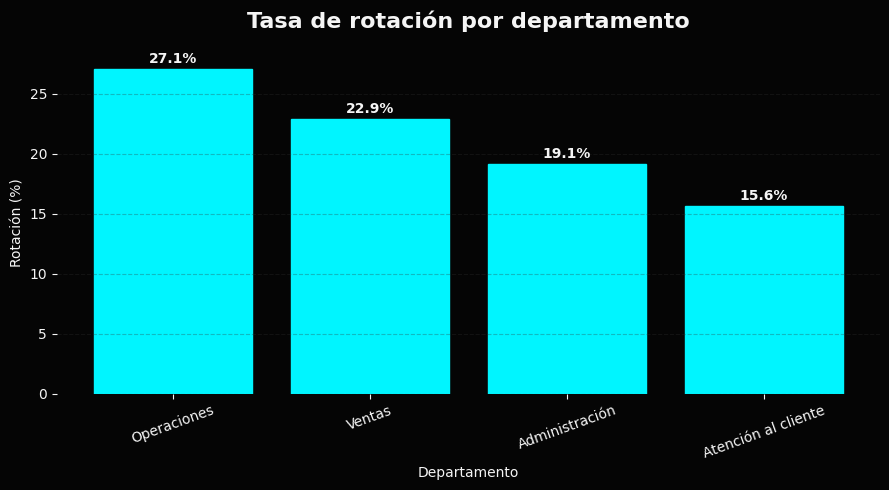

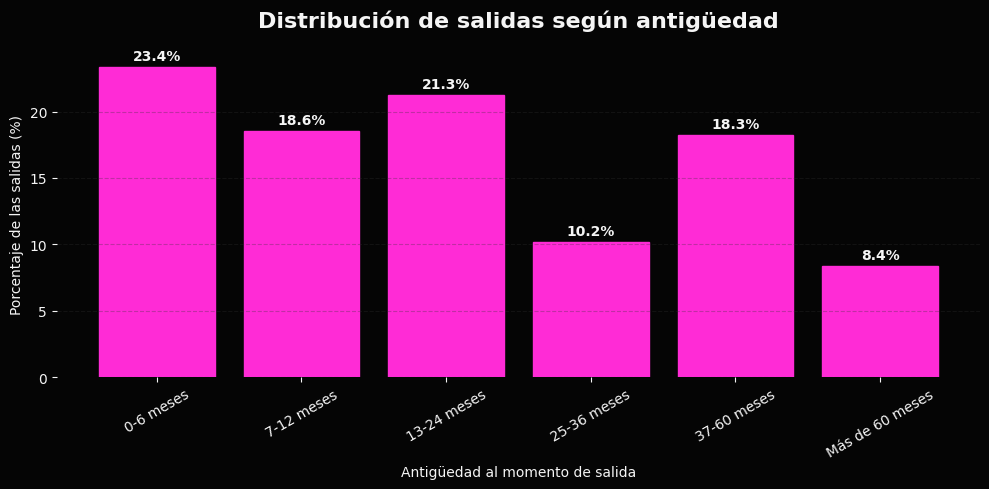

In [ ]:
# ==========================================
# VISUALIZACIONES DARK / NEÓN
# ==========================================

fondo = "#050505"
texto = "#F5F5F5"
grid = "#333333"

cyan = "#00F5FF"
magenta = "#FF2BD6"


# ==========================================
# GRÁFICO 1
# Rotación por departamento
# ==========================================

fig, ax = plt.subplots(
    figsize=(9, 5)
)

fig.patch.set_facecolor(fondo)
ax.set_facecolor(fondo)

barras = ax.bar(
    rotacion_departamento["departamento"],
    rotacion_departamento["tasa_rotacion"],
    color=cyan,
    edgecolor=cyan
)

ax.set_title(
    "Tasa de rotación por departamento",
    color=texto,
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_ylabel(
    "Rotación (%)",
    color=texto
)

ax.set_xlabel(
    "Departamento",
    color=texto
)

ax.tick_params(
    colors=texto
)

plt.xticks(
    rotation=20
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30,
    color=grid
)

for barra, valor in zip(
    barras,
    rotacion_departamento["tasa_rotacion"]
):

    ax.text(
        barra.get_x()
        + barra.get_width() / 2,

        barra.get_height() + 0.5,

        f"{valor:.1f}%",

        ha="center",
        color=texto,
        fontweight="bold"
    )

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()


# ==========================================
# GRÁFICO 2
# Distribución de salidas por antigüedad
# ==========================================

fig, ax = plt.subplots(
    figsize=(10, 5)
)

fig.patch.set_facecolor(fondo)
ax.set_facecolor(fondo)

barras = ax.bar(
    distribucion_salidas_antiguedad[
        "rango_antiguedad"
    ].astype(str),

    distribucion_salidas_antiguedad[
        "porcentaje_salidas"
    ],

    color=magenta,
    edgecolor=magenta
)

ax.set_title(
    "Distribución de salidas según antigüedad",
    color=texto,
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_ylabel(
    "Porcentaje de las salidas (%)",
    color=texto
)

ax.set_xlabel(
    "Antigüedad al momento de salida",
    color=texto
)

ax.tick_params(
    colors=texto
)

plt.xticks(
    rotation=30
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30,
    color=grid
)

for barra, valor in zip(
    barras,
    distribucion_salidas_antiguedad[
        "porcentaje_salidas"
    ]
):

    ax.text(
        barra.get_x()
        + barra.get_width() / 2,

        barra.get_height() + 0.5,

        f"{valor:.1f}%",

        ha="center",
        color=texto,
        fontweight="bold"
    )

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

## 6. Validación del análisis con SQL

Además del análisis en Python, se utiliza SQL para responder algunas de las mismas preguntas de negocio y demostrar el uso de consultas sobre una base estructurada.

In [ ]:
import sqlite3

conn = sqlite3.connect(
    ":memory:"
)

df_sql = df.copy()

for columna in [
    "rango_antiguedad",
    "rango_horas_extra",
    "rango_ausencia"
]:

    df_sql[columna] = (
        df_sql[columna]
        .astype(str)
    )


df_sql["fecha_ingreso"] = (
    df_sql["fecha_ingreso"]
    .dt.strftime("%Y-%m-%d")
)

df_sql["fecha_salida"] = (
    df_sql["fecha_salida"]
    .dt.strftime("%Y-%m-%d")
)


df_sql.to_sql(
    "empleados",
    conn,
    if_exists="replace",
    index=False
)


# ==========================================
# 1. Rotación general
# ==========================================

consulta_general = """
SELECT
    COUNT(*) AS empleados,
    SUM(salio_empresa) AS salidas,
    ROUND(
        AVG(salio_empresa) * 100,
        2
    ) AS tasa_rotacion
FROM empleados;
"""

print("ROTACIÓN GENERAL")

display(
    pd.read_sql_query(
        consulta_general,
        conn
    )
)


# ==========================================
# 2. Rotación por departamento
# ==========================================

consulta_departamento = """
SELECT
    departamento,
    COUNT(*) AS empleados,
    SUM(salio_empresa) AS salidas,
    ROUND(
        AVG(salio_empresa) * 100,
        2
    ) AS tasa_rotacion
FROM empleados
GROUP BY departamento
ORDER BY tasa_rotacion DESC;
"""

print("\nROTACIÓN POR DEPARTAMENTO")

display(
    pd.read_sql_query(
        consulta_departamento,
        conn
    )
)


# ==========================================
# 3. Departamento + turno
# ==========================================

consulta_segmento = """
SELECT
    departamento,
    turno,
    COUNT(*) AS empleados,
    SUM(salio_empresa) AS salidas,
    ROUND(
        AVG(salio_empresa) * 100,
        2
    ) AS tasa_rotacion
FROM empleados
GROUP BY
    departamento,
    turno
ORDER BY tasa_rotacion DESC;
"""

print("\nDEPARTAMENTO + TURNO")

display(
    pd.read_sql_query(
        consulta_segmento,
        conn
    )
)

ROTACIÓN GENERAL


,empleados,salidas,tasa_rotacion
0,1500,334,22.27



ROTACIÓN POR DEPARTAMENTO


,departamento,empleados,salidas,tasa_rotacion
0,Operaciones,561,152,27.09
1,Ventas,376,86,22.87
2,Administración,230,44,19.13
3,Atención al cliente,333,52,15.62



DEPARTAMENTO + TURNO


,departamento,turno,empleados,salidas,tasa_rotacion
0,Operaciones,Noche,84,26,30.95
1,Operaciones,Tarde,201,60,29.85
2,Ventas,Noche,58,17,29.31
3,Ventas,Mañana,155,38,24.52
4,Atención al cliente,Noche,49,12,24.49
5,Operaciones,Mañana,276,66,23.91
6,Administración,Mañana,112,26,23.21
7,Ventas,Tarde,163,31,19.02
8,Administración,Noche,33,6,18.18
9,Atención al cliente,Mañana,158,26,16.46


## 7. Conclusiones y recomendaciones

El análisis identifica a **Operaciones** como el departamento con mayor rotación y al turno **Noche** como el de mayor tasa de salida.

Sin embargo, el segmento **Operaciones + Tarde** también debe considerarse prioritario debido al mayor volumen de empleados y salidas.

El análisis de antigüedad muestra que **63,17% de las salidas observadas ocurrieron durante los primeros 24 meses de permanencia**, por lo que conviene investigar especialmente los procesos de onboarding, adaptación y seguimiento durante esta etapa.

También se observan tasas superiores en empleados con contratos a plazo fijo, mayor cantidad de horas extra y niveles bajos de satisfacción.

### Recomendaciones

- Priorizar el análisis de retención en Operaciones.
- Revisar condiciones de los turnos Noche y Tarde.
- Fortalecer seguimiento y onboarding durante los primeros 24 meses.
- Investigar las causas de salida de trabajadores con contrato a plazo fijo.
- Monitorear horas extra y satisfacción como posibles señales de riesgo.
- Incorporar en futuros análisis variables como salario, jefatura, motivos de renuncia, tiempo de traslado y oportunidades de crecimiento.

### Limitaciones

El dataset es sintético y los resultados muestran asociaciones dentro del escenario simulado. No permiten establecer relaciones causales ni representan el comportamiento real de una empresa.

In [ ]:
df.to_csv(
    "/content/datos_rotacion_personal.csv",
    index=False
)

print(
    "Dataset exportado correctamente."
)

Dataset exportado correctamente.
